In [1]:
import torch
from torch import nn

print("torch version:", torch.__version__)

# device-agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Google Drive mount
from google.colab import drive
drive.mount('/content/drive')

# Zip file check
from pathlib import Path
ZIP_FILE_PATH = '/content/drive/MyDrive/pneumonia _x_ray.zip'
print("Zip exists:", Path(ZIP_FILE_PATH).exists())

torch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Mounted at /content/drive
Zip exists: True


**Zip extract aur paths check**

In [2]:
import zipfile
from pathlib import Path

ZIP_FILE_PATH = '/content/drive/MyDrive/pneumonia _x_ray.zip'
EXTRACT_DIR = '/content/chest_xray'

# Extract
print("Extracting...")
with zipfile.ZipFile(ZIP_FILE_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)
print("Done")

!ls -la {EXTRACT_DIR}

# Paths check
DATA_DIR = Path(EXTRACT_DIR)
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'val'
TEST_DIR = DATA_DIR / 'test'

print(f"\nTrain: {TRAIN_DIR.exists()}")
print(f"Val:   {VAL_DIR.exists()}")
print(f"Test:  {TEST_DIR.exists()}")


Extracting...
Done
total 20
drwxr-xr-x 5 root root 4096 Nov 18 12:38 .
drwxr-xr-x 1 root root 4096 Nov 18 12:37 ..
drwxr-xr-x 4 root root 4096 Nov 18 12:37 test
drwxr-xr-x 4 root root 4096 Nov 18 12:38 train
drwxr-xr-x 4 root root 4096 Nov 18 12:38 val

Train: True
Val:   True
Test:  True


In [3]:
from pathlib import Path

DATA_DIR = Path('/content/chest_xray')
total = 0
for split in ['train', 'val', 'test']:
    for cls in ['NORMAL', 'PNEUMONIA']:
        folder = DATA_DIR / split / cls
        n = len([f for f in folder.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]) if folder.exists() else 0
        total += n
        print(f"{split:5s} | {cls:10s} | {n}")
print("-" * 30)
print("TOTAL images:", total)

train | NORMAL     | 1341
train | PNEUMONIA  | 3875
val   | NORMAL     | 8
val   | PNEUMONIA  | 8
test  | NORMAL     | 234
test  | PNEUMONIA  | 390
------------------------------
TOTAL images: 5856


**Imports aur timm install**

In [4]:
!pip install -q timm tqdm scikit-learn seaborn

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from PIL import Image
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import json
from datetime import datetime
from pathlib import Path
from collections import Counter
import timm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print("timm version:", timm.__version__)

Device: cuda
GPU: Tesla T4
timm version: 1.0.31


**Dataset class, transforms aur dataloaders**

In [5]:
# ---------- Dataset Class ----------
class ChestXRayDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform
        self.images = []
        self.labels = []

        normal_dir = self.root_dir / "NORMAL"
        if normal_dir.exists():
            for img in sorted(normal_dir.iterdir()):
                if img.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                    self.images.append(img)
                    self.labels.append(0)

        pneumonia_dir = self.root_dir / "PNEUMONIA"
        if pneumonia_dir.exists():
            for img in sorted(pneumonia_dir.iterdir()):
                if img.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                    self.images.append(img)
                    self.labels.append(1)

        counts = Counter(self.labels)
        print(f"{self.root_dir.name}: {len(self.images)} images | NORMAL: {counts[0]} | PNEUMONIA: {counts[1]}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label


# ---------- Transforms ----------
IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2)
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ---------- Datasets ----------
DATA_DIR = Path('/content/chest_xray')
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR   = DATA_DIR / 'val'
TEST_DIR  = DATA_DIR / 'test'

train_dataset = ChestXRayDataset(TRAIN_DIR, transform=train_transform)
val_dataset   = ChestXRayDataset(VAL_DIR,   transform=val_transform)
test_dataset  = ChestXRayDataset(TEST_DIR,  transform=val_transform)

# ---------- Weighted Sampler (imbalance fix) ----------
counts = Counter(train_dataset.labels)
class_weights = {cls: 1.0 / count for cls, count in counts.items()}
sample_weights = [class_weights[label] for label in train_dataset.labels]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

# ---------- Dataloaders ----------
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Dataloaders ready")

train: 5216 images | NORMAL: 1341 | PNEUMONIA: 3875
val: 16 images | NORMAL: 8 | PNEUMONIA: 8
test: 624 images | NORMAL: 234 | PNEUMONIA: 390
Dataloaders ready


In [6]:
import shutil
from sklearn.model_selection import train_test_split

SRC = Path('/content/chest_xray')
DST = Path('/content/xray_256')
if DST.exists():
    shutil.rmtree(DST)

def resize_copy(src_dir, dst_dir, prefix):
    dst_dir.mkdir(parents=True, exist_ok=True)
    files = [f for f in src_dir.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
    for f in tqdm(files, desc=f"{prefix} {src_dir.name}"):
        img = Image.open(f).convert('RGB').resize((256, 256))
        img.save(dst_dir / f"{prefix}_{f.stem}.jpg", quality=95)

# train + val ek jagah (naya split baad mein hoga), test alag
for split, out in [('train', 'trainval'), ('val', 'trainval'), ('test', 'test')]:
    for cls in ['NORMAL', 'PNEUMONIA']:
        resize_copy(SRC / split / cls, DST / out / cls, split)

# ---------- Datasets ----------
full_train = ChestXRayDataset(DST / 'trainval', transform=train_transform)  # augmentation wala
full_val   = ChestXRayDataset(DST / 'trainval', transform=val_transform)    # bina augmentation
test_dataset = ChestXRayDataset(DST / 'test', transform=val_transform)

# ---------- 90/10 stratified split ----------
idx = np.arange(len(full_train))
train_idx, val_idx = train_test_split(idx, test_size=0.10, stratify=full_train.labels, random_state=42)

train_dataset = torch.utils.data.Subset(full_train, train_idx)
val_dataset   = torch.utils.data.Subset(full_val, val_idx)
train_dataset.labels = [full_train.labels[i] for i in train_idx]   # baaki cells ko chahiye
val_dataset.labels   = [full_val.labels[i] for i in val_idx]

print("Train:", len(train_dataset), Counter(train_dataset.labels))
print("Val:  ", len(val_dataset),   Counter(val_dataset.labels))

# ---------- Weighted Sampler ----------
counts = Counter(train_dataset.labels)
class_weights = {cls: 1.0 / c for cls, c in counts.items()}
sample_weights = [class_weights[l] for l in train_dataset.labels]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

# ---------- Dataloaders ----------
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print("Dataloaders ready")

test PNEUMONIA: 100%|██████████| 390/390 [00:06<00:00, 58.57it/s]


trainval: 5232 images | NORMAL: 1349 | PNEUMONIA: 3883
trainval: 5232 images | NORMAL: 1349 | PNEUMONIA: 3883
test: 624 images | NORMAL: 234 | PNEUMONIA: 390
Train: 4708 Counter({1: 3494, 0: 1214})
Val:   524 Counter({1: 389, 0: 135})
Dataloaders ready


**Model build, loss, optimizer aur scheduler**

In [7]:
def build_model(model_name='efficientnet', num_classes=2, dropout=0.4):
    if model_name == 'efficientnet':
        model = timm.create_model('efficientnet_b2', pretrained=True, drop_rate=dropout)
        num_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(256, num_classes)
        )
        print(f"EfficientNet-B2 loaded | Params: {sum(p.numel() for p in model.parameters()):,}")

    elif model_name == 'densenet':
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        num_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(256, num_classes)
        )
        print(f"DenseNet121 loaded | Params: {sum(p.numel() for p in model.parameters()):,}")
    else:
        raise ValueError("model_name must be 'efficientnet' or 'densenet'")

    return model.to(device)

model = build_model('efficientnet')

# ---------- Loss + Optimizer + Scheduler ----------
counts = Counter(train_dataset.labels)
total = sum(counts.values())
weights = torch.tensor([total / counts[0], total / counts[1]], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)

NUM_EPOCHS    = 20
LEARNING_RATE = 0.0001

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

print(f"Setup ready | Epochs: {NUM_EPOCHS} | LR: {LEARNING_RATE}")
print(f"Class weights: NORMAL={weights[0]:.3f}, PNEUMONIA={weights[1]:.3f}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 36.8MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet-B2 loaded | Params: 8,062,212
Setup ready | Epochs: 20 | LR: 0.0001
Class weights: NORMAL=3.878, PNEUMONIA=1.347


**Train/validate functions aur training loop**

In [8]:
# ---------- Pehle check: zaroori cells chal chuke hain? ----------
required = ['model', 'criterion', 'optimizer', 'scheduler', 'train_loader', 'val_loader', 'NUM_EPOCHS', 'train_dataset']
missing = [n for n in required if n not in globals()]
assert not missing, f"Pehle yeh cells chalao (5B aur 6): {missing}"
assert len(train_dataset) < 5000 and len(val_dataset) > 100, \
    "Cell 5B chalna baqi hai (val set abhi 16 images ka hai)"

# ---------- Naam yahan se change kar sakte ho ----------
FOLDER_NAME     = 'Hybrid_CNN_SVM_Pneumonia'
MODEL_FILE_NAME = 'hybrid_effnet_cnn.pth'

SAVE_DIR = Path('/content/drive/MyDrive') / FOLDER_NAME
SAVE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = SAVE_DIR / MODEL_FILE_NAME
LAST_PATH  = SAVE_DIR / 'last_checkpoint.pth'

# ---------- Train / Validate functions ----------
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(dataloader, desc="Training", leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predicted = outputs.argmax(1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        pbar.set_postfix(loss=f'{loss.item():.4f}', acc=f'{100*correct/total:.1f}%')
    return running_loss / total, 100 * correct / total


def validate(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc="Validating", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predicted = outputs.argmax(1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return running_loss / total, 100 * correct / total, all_preds, all_labels


# ---------- Training Loop with Early Stopping ----------
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0
best_val_loss = float('inf')
PATIENCE = 5
patience_counter = 0

print("=" * 60)
print("TRAINING STARTED")
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")
print(f"Best model will be saved at: {MODEL_PATH}")
print("=" * 60)

for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 60)

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, _, _ = validate(model, val_loader, criterion, device)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    gap = train_acc - val_acc
    overfit_warning = "  OVERFITTING!" if gap > 10 else ""

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.2f}%")
    print(f"Gap (Train-Val): {gap:.2f}%{overfit_warning}")

    # Last checkpoint (disconnect se bachne ke liye)
    torch.save({'epoch': epoch + 1, 'model_state_dict': model.state_dict(), 'history': history}, LAST_PATH)

    # Best model: val acc behtar ho, ya barabar ho aur val loss kam ho
    improved = (val_acc > best_val_acc) or (val_acc == best_val_acc and val_loss < best_val_loss)
    if improved:
        best_val_acc = val_acc
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), MODEL_PATH)
        print(f"Best model saved! Val Acc: {val_acc:.2f}%")
    else:
        patience_counter += 1
        print(f"No improvement ({patience_counter}/{PATIENCE})")

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

print("\n" + "=" * 60)
print(f"TRAINING DONE! Best Val Acc: {best_val_acc:.2f}%")
print("=" * 60)

TRAINING STARTED
Train: 4708 | Val: 524
Best model will be saved at: /content/drive/MyDrive/Hybrid_CNN_SVM_Pneumonia/hybrid_effnet_cnn.pth

Epoch 1/20
------------------------------------------------------------


Train Loss: 0.1987 | Train Acc: 88.59%
Val   Loss: 0.1673 | Val   Acc: 90.08%
Gap (Train-Val): -1.48%
Best model saved! Val Acc: 90.08%

Epoch 2/20
------------------------------------------------------------


Train Loss: 0.0778 | Train Acc: 96.13%
Val   Loss: 0.1570 | Val   Acc: 91.60%
Gap (Train-Val): 4.53%
Best model saved! Val Acc: 91.60%

Epoch 3/20
------------------------------------------------------------


Train Loss: 0.0622 | Train Acc: 97.26%
Val   Loss: 0.1663 | Val   Acc: 90.65%
Gap (Train-Val): 6.61%
No improvement (1/5)

Epoch 4/20
------------------------------------------------------------


Train Loss: 0.0423 | Train Acc: 97.96%
Val   Loss: 0.1115 | Val   Acc: 93.70%
Gap (Train-Val): 4.26%
Best model saved! Val Acc: 93.70%

Epoch 5/20
------------------------------------------------------------


Train Loss: 0.0412 | Train Acc: 98.19%
Val   Loss: 0.1683 | Val   Acc: 91.98%
Gap (Train-Val): 6.21%
No improvement (1/5)

Epoch 6/20
------------------------------------------------------------


... (11 outputs left out)

Train Loss: 0.0117 | Train Acc: 99.45%
Val   Loss: 0.0930 | Val   Acc: 97.71%
Gap (Train-Val): 1.74%
Best model saved! Val Acc: 97.71%

Epoch 18/20
------------------------------------------------------------


Train Loss: 0.0126 | Train Acc: 99.70%
Val   Loss: 0.1332 | Val   Acc: 95.04%
Gap (Train-Val): 4.66%
No improvement (1/5)

Epoch 19/20
------------------------------------------------------------


Train Loss: 0.0083 | Train Acc: 99.64%
Val   Loss: 0.1007 | Val   Acc: 97.52%
Gap (Train-Val): 2.12%
No improvement (2/5)

Epoch 20/20
------------------------------------------------------------


Train Loss: 0.0098 | Train Acc: 99.64%
Val   Loss: 0.1001 | Val   Acc: 96.56%
Gap (Train-Val): 3.07%
No improvement (3/5)

TRAINING DONE! Best Val Acc: 97.71%


Best model loaded: /content/drive/MyDrive/Hybrid_CNN_SVM_Pneumonia/hybrid_effnet_cnn.pth


Testing: 100%|██████████| 20/20 [00:06<00:00,  3.30it/s]



CNN Test Accuracy: 94.23%
CNN Test AUC:      0.9853

              precision    recall  f1-score   support

      NORMAL     0.9670    0.8761    0.9193       234
   PNEUMONIA     0.9296    0.9821    0.9551       390

    accuracy                         0.9423       624
   macro avg     0.9483    0.9291    0.9372       624
weighted avg     0.9436    0.9423    0.9417       624



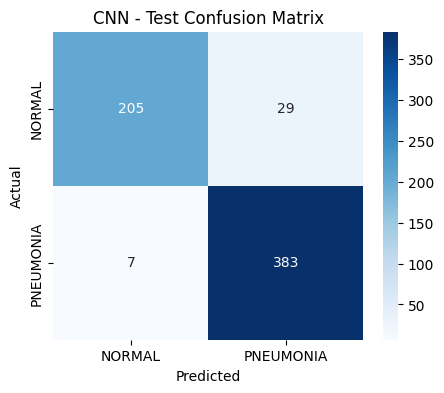

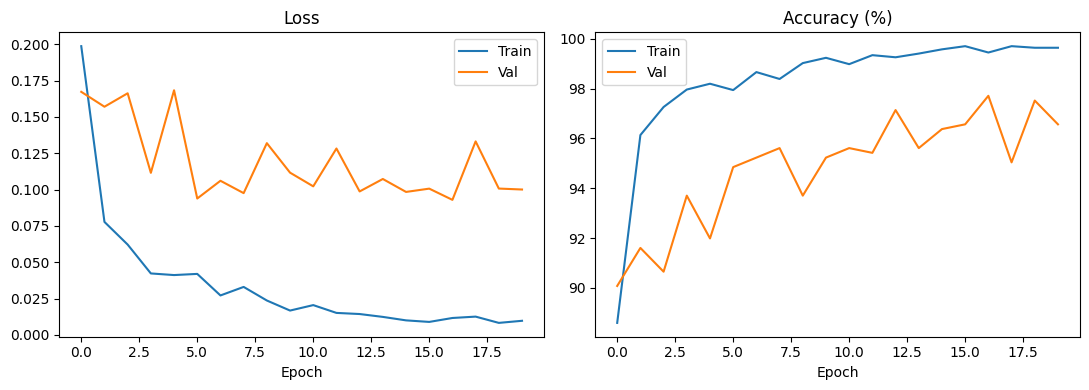

In [9]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score
import seaborn as sns

# ---------- Best model load ----------
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()
print("Best model loaded:", MODEL_PATH)

# ---------- Test evaluation ----------
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

cnn_acc = accuracy_score(all_labels, all_preds)
cnn_auc = roc_auc_score(all_labels, all_probs)
print(f"\nCNN Test Accuracy: {cnn_acc*100:.2f}%")
print(f"CNN Test AUC:      {cnn_auc:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=['NORMAL', 'PNEUMONIA'], digits=4))

# ---------- Confusion matrix ----------
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'], yticklabels=['NORMAL', 'PNEUMONIA'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('CNN - Test Confusion Matrix')
plt.show()

# ---------- Training curves ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history['train_loss'], label='Train'); ax[0].plot(history['val_loss'], label='Val')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(history['train_acc'], label='Train'); ax[1].plot(history['val_acc'], label='Val')
ax[1].set_title('Accuracy (%)'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

**Feature extraction (CNN se) aur Drive mein save**

In [10]:
# ---------- Feature extractor: CNN ki 256-dim hidden layer ----------
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

def extract_features(x):
    f = model.forward_features(x)       # conv features
    f = model.global_pool(f)            # pooled -> (B, 1408)
    f = model.classifier[:3](f)         # Dropout -> Linear(1408,256) -> ReLU  (eval mode: dropout off)
    return f

# Train features BINA augmentation ke (val_transform wala dataset, train indices)
feat_train_ds = torch.utils.data.Subset(full_val, train_idx)
feat_train_loader = DataLoader(feat_train_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

def get_features(loader, name):
    feats, labels = [], []
    with torch.no_grad():
        for images, lbls in tqdm(loader, desc=name):
            f = extract_features(images.to(device))
            feats.append(f.cpu().numpy())
            labels.extend(lbls.numpy())
    return np.concatenate(feats), np.array(labels)

X_train, y_train = get_features(feat_train_loader, "Train features")
X_val,   y_val   = get_features(val_loader,        "Val features")
X_test,  y_test  = get_features(test_loader,       "Test features")

print("\nShapes:")
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

# Drive mein save (taake dobara extract na karna paray)
np.savez_compressed(SAVE_DIR / 'cnn_features.npz',
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test)
print("Features saved:", SAVE_DIR / 'cnn_features.npz')

Test features: 100%|██████████| 20/20 [00:03<00:00,  5.52it/s]



Shapes:
X_train: (4708, 256) | X_val: (524, 256) | X_test: (624, 256)
Features saved: /content/drive/MyDrive/Hybrid_CNN_SVM_Pneumonia/cnn_features.npz


**SVM train, tuning (val set par) aur test evaluation**

kernel       C   gamma | val_acc  val_bal_acc  time
linear    0.01   scale |  98.66%   98.13%      0.2s
linear     0.1   scale |  98.47%   97.76%      0.1s
linear       1   scale |  98.28%   97.39%      0.1s
linear      10   scale |  98.28%   97.39%      0.1s
rbf        0.1   scale |  98.66%   98.37%      0.2s
rbf        0.1   0.001 |  98.47%   98.25%      0.3s
rbf        0.1    0.01 |  98.66%   98.37%      0.2s
rbf          1   scale |  98.66%   98.13%      0.1s
rbf          1   0.001 |  98.47%   98.00%      0.2s
rbf          1    0.01 |  98.66%   98.13%      0.4s
rbf         10   scale |  98.66%   98.13%      0.2s
rbf         10   0.001 |  98.66%   98.13%      0.1s
rbf         10    0.01 |  98.47%   97.76%      0.2s
rbf        100   scale |  98.09%   97.26%      0.2s
rbf        100   0.001 |  98.47%   97.76%      0.1s
rbf        100    0.01 |  98.28%   97.39%      0.1s

Best SVM -> kernel=rbf, C=0.1, gamma=scale | val acc=98.66%

HYBRID (CNN + SVM) Test Accuracy: 91.67%
HYBRID (CNN +

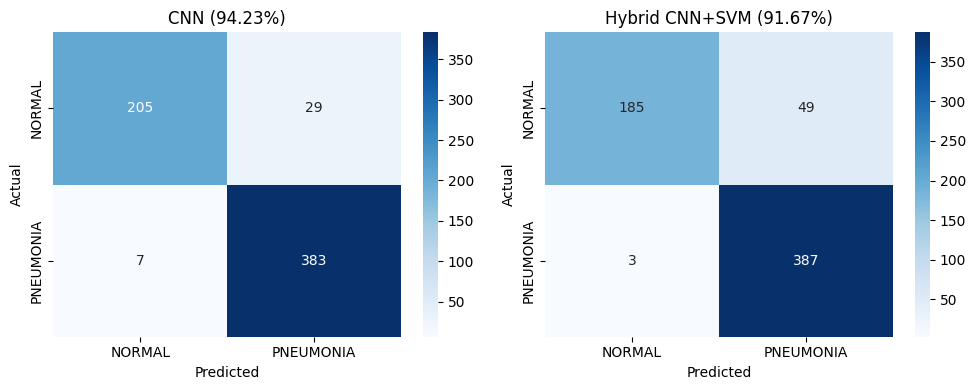

Model                  Accuracy        AUC
---------------------------------------------
CNN (softmax)            94.23%     0.9853
Hybrid CNN + SVM         91.67%     0.9360
SVM saved: /content/drive/MyDrive/Hybrid_CNN_SVM_Pneumonia/svm_classifier.joblib


In [12]:
import joblib, time
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, roc_auc_score, balanced_accuracy_score)

# ---------- Scale (SVM ke liye zaroori) ----------
scaler = StandardScaler().fit(X_train)
Xtr, Xva, Xte = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

# ---------- Hyperparameter search: train par fit, VAL par score (test ko haath nahi lagate) ----------
grid = [('linear', C, 'scale') for C in [0.01, 0.1, 1, 10]] + \
       [('rbf', C, g) for C in [0.1, 1, 10, 100] for g in ['scale', 0.001, 0.01]]

results = []
print(f"{'kernel':7s} {'C':>6s} {'gamma':>7s} | val_acc  val_bal_acc  time")
for kernel, C, gamma in grid:
    t0 = time.time()
    svm = SVC(kernel=kernel, C=C, gamma=gamma, class_weight='balanced')
    svm.fit(Xtr, y_train)
    pv = svm.predict(Xva)
    acc, bacc = accuracy_score(y_val, pv), balanced_accuracy_score(y_val, pv)
    results.append((bacc, acc, kernel, C, gamma))
    print(f"{kernel:7s} {C:>6} {str(gamma):>7s} | {acc*100:6.2f}%  {bacc*100:6.2f}%     {time.time()-t0:4.1f}s")

# FIX: sirf score par compare (balanced acc, phir acc)
best = max(results, key=lambda r: (r[0], r[1]))
_, best_acc, best_kernel, best_C, best_gamma = best
print(f"\nBest SVM -> kernel={best_kernel}, C={best_C}, gamma={best_gamma} | val acc={best_acc*100:.2f}%")

# ---------- Best parameters se final SVM ----------
svm = SVC(kernel=best_kernel, C=best_C, gamma=best_gamma, class_weight='balanced')
svm.fit(Xtr, y_train)

# ---------- Test evaluation ----------
svm_pred  = svm.predict(Xte)
svm_score = svm.decision_function(Xte)
svm_acc   = accuracy_score(y_test, svm_pred)
svm_auc   = roc_auc_score(y_test, svm_score)

print(f"\nHYBRID (CNN + SVM) Test Accuracy: {svm_acc*100:.2f}%")
print(f"HYBRID (CNN + SVM) Test AUC:      {svm_auc:.4f}\n")
print(classification_report(y_test, svm_pred, target_names=['NORMAL', 'PNEUMONIA'], digits=4))

# ---------- Confusion matrix: CNN vs Hybrid ----------
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, preds, title in [(ax[0], all_preds, f'CNN ({cnn_acc*100:.2f}%)'),
                        (ax[1], svm_pred,  f'Hybrid CNN+SVM ({svm_acc*100:.2f}%)')]:
    sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt='d', cmap='Blues', ax=a,
                xticklabels=['NORMAL', 'PNEUMONIA'], yticklabels=['NORMAL', 'PNEUMONIA'])
    a.set_title(title); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

# ---------- Comparison ----------
print("=" * 45)
print(f"{'Model':20s} {'Accuracy':>10s} {'AUC':>10s}")
print("-" * 45)
print(f"{'CNN (softmax)':20s} {cnn_acc*100:9.2f}% {cnn_auc:10.4f}")
print(f"{'Hybrid CNN + SVM':20s} {svm_acc*100:9.2f}% {svm_auc:10.4f}")
print("=" * 45)

# ---------- Save ----------
joblib.dump({'svm': svm, 'scaler': scaler}, SAVE_DIR / 'svm_classifier.joblib')
print("SVM saved:", SAVE_DIR / 'svm_classifier.joblib')

**Feature variants ka comparison**

In [13]:
from sklearn.model_selection import GridSearchCV

# ---------- 1408-dim pooled features (classifier head se pehle) ----------
def extract_pooled(x):
    return model.global_pool(model.forward_features(x))

def get_feats(loader, fn, name):
    feats, labels = [], []
    model.eval()
    with torch.no_grad():
        for images, lbls in tqdm(loader, desc=name):
            feats.append(fn(images.to(device)).cpu().numpy())
            labels.extend(lbls.numpy())
    return np.concatenate(feats), np.array(labels)

P_train, _ = get_feats(feat_train_loader, extract_pooled, "Pooled train")
P_val,   _ = get_feats(val_loader,        extract_pooled, "Pooled val")
P_test,  _ = get_feats(test_loader,       extract_pooled, "Pooled test")
print("Pooled shapes:", P_train.shape, P_val.shape, P_test.shape)

# ---------- Helper: train par fit, val par tuning, test par report ----------
small_grid = [('linear', C, 'scale') for C in [0.01, 0.1, 1]] + \
             [('rbf', C, 'scale') for C in [0.1, 1, 10]]

def fit_eval(name, A, ya, V, yv, T, yt):
    sc = StandardScaler().fit(A)
    A_, V_, T_ = sc.transform(A), sc.transform(V), sc.transform(T)
    scored = []
    for kernel, C, gamma in small_grid:
        s = SVC(kernel=kernel, C=C, gamma=gamma, class_weight='balanced').fit(A_, ya)
        scored.append((balanced_accuracy_score(yv, s.predict(V_)), accuracy_score(yv, s.predict(V_)), kernel, C, gamma))
    _, _, k, C, g = max(scored, key=lambda r: (r[0], r[1]))
    s = SVC(kernel=k, C=C, gamma=g, class_weight='balanced').fit(A_, ya)
    pred, score = s.predict(T_), s.decision_function(T_)
    cm = confusion_matrix(yt, pred)
    return name, f"{k} C={C}", accuracy_score(yt, pred), roc_auc_score(yt, score), cm[0,0], cm[0,1], cm[1,0], cm[1,1]

rows = []
rows.append(fit_eval("SVM on 256-d (train feats)",  X_train, y_train, X_val, y_val, X_test, y_test))
rows.append(fit_eval("SVM on 1408-d (train feats)", P_train, y_train, P_val, y_val, P_test, y_test))

# ---------- Variant: SVM ko val features par train karna (CNN ne val kabhi train mein nahi dekha) ----------
for nm, Xv_, Pv_ in [("256-d", X_val, None), ("1408-d", P_val, None)]:
    Xa = X_val if nm == "256-d" else P_val
    Xt = X_test if nm == "256-d" else P_test
    sc = StandardScaler().fit(Xa)
    gs = GridSearchCV(SVC(class_weight='balanced'),
                      {'kernel': ['linear', 'rbf'], 'C': [0.01, 0.1, 1, 10]},
                      scoring='balanced_accuracy', cv=5).fit(sc.transform(Xa), y_val)
    pred = gs.predict(sc.transform(Xt)); score = gs.decision_function(sc.transform(Xt))
    cm = confusion_matrix(y_test, pred)
    rows.append((f"SVM on {nm} (fit on VAL only)", f"{gs.best_params_['kernel']} C={gs.best_params_['C']}",
                 accuracy_score(y_test, pred), roc_auc_score(y_test, score), cm[0,0], cm[0,1], cm[1,0], cm[1,1]))

# ---------- Comparison table (test set) ----------
print("\n" + "=" * 100)
print(f"{'Model':32s} {'SVM params':14s} {'Acc':>8s} {'AUC':>8s} | TN   FP   FN   TP")
print("-" * 100)
cm0 = confusion_matrix(y_test, all_preds)
print(f"{'CNN (softmax) - baseline':32s} {'-':14s} {cnn_acc*100:7.2f}% {cnn_auc:8.4f} | {cm0[0,0]:<4d} {cm0[0,1]:<4d} {cm0[1,0]:<4d} {cm0[1,1]:<4d}")
for n, p, a, u, tn, fp, fn, tp in rows:
    print(f"{n:32s} {p:14s} {a*100:7.2f}% {u:8.4f} | {tn:<4d} {fp:<4d} {fn:<4d} {tp:<4d}")
print("=" * 100)

Pooled test: 100%|██████████| 20/20 [00:03<00:00,  6.49it/s]


Pooled shapes: (4708, 1408) (524, 1408) (624, 1408)

Model                            SVM params          Acc      AUC | TN   FP   FN   TP
----------------------------------------------------------------------------------------------------
CNN (softmax) - baseline         -                94.23%   0.9853 | 205  29   7    383 
SVM on 256-d (train feats)       rbf C=0.1        91.67%   0.9360 | 185  49   3    387 
SVM on 1408-d (train feats)      rbf C=0.1        89.58%   0.9788 | 171  63   2    388 
SVM on 256-d (fit on VAL only)   linear C=0.1     91.51%   0.9338 | 184  50   3    387 
SVM on 1408-d (fit on VAL only)  rbf C=0.1        91.99%   0.9848 | 188  46   4    386 


Threshold tuning (CNN vs SVM, dono val par tune, test par report)

Model                         Threshold      Acc      AUC | TN   FP   FN   TP
------------------------------------------------------------------------------------------
CNN (softmax)                     0.137   92.31%   0.9853 | 189  45   3    387 
SVM 256-d                         0.108   92.15%   0.9360 | 188  46   3    387 
SVM 1408-d                        0.021   89.74%   0.9788 | 172  62   2    388 


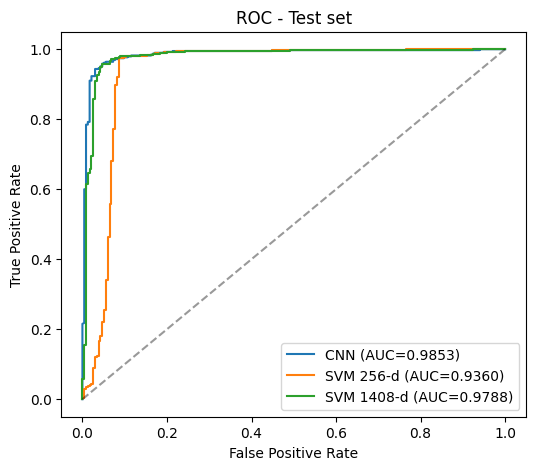

In [14]:
from sklearn.metrics import roc_curve

# ---------- Scores nikalna ----------
# CNN val probabilities
model.eval()
cnn_val_probs = []
with torch.no_grad():
    for images, _ in val_loader:
        cnn_val_probs.extend(torch.softmax(model(images.to(device)), dim=1)[:, 1].cpu().numpy())
cnn_val_probs = np.array(cnn_val_probs)
cnn_test_probs = np.array(all_probs)

# SVM scores (train features par fit)
def svm_scores(A, V, T):
    sc = StandardScaler().fit(A)
    s = SVC(kernel='rbf', C=0.1, gamma='scale', class_weight='balanced').fit(sc.transform(A), y_train)
    return s.decision_function(sc.transform(V)), s.decision_function(sc.transform(T))

s256_val,  s256_test  = svm_scores(X_train, X_val, X_test)
s1408_val, s1408_test = svm_scores(P_train, P_val, P_test)

# ---------- Threshold: val par Youden's J (TPR - FPR) maximize ----------
def best_threshold(s_val):
    fpr, tpr, thr = roc_curve(y_val, s_val)
    return thr[np.argmax(tpr - fpr)]

print("=" * 90)
print(f"{'Model':28s} {'Threshold':>10s} {'Acc':>8s} {'AUC':>8s} | TN   FP   FN   TP")
print("-" * 90)
for name, sv, st in [("CNN (softmax)", cnn_val_probs, cnn_test_probs),
                     ("SVM 256-d",      s256_val,      s256_test),
                     ("SVM 1408-d",     s1408_val,     s1408_test)]:
    t = best_threshold(sv)
    pred = (st >= t).astype(int)
    cm = confusion_matrix(y_test, pred)
    print(f"{name:28s} {t:10.3f} {accuracy_score(y_test, pred)*100:7.2f}% {roc_auc_score(y_test, st):8.4f} | "
          f"{cm[0,0]:<4d} {cm[0,1]:<4d} {cm[1,0]:<4d} {cm[1,1]:<4d}")
print("=" * 90)

# ---------- ROC curves (test) ----------
plt.figure(figsize=(6, 5))
for name, st in [("CNN", cnn_test_probs), ("SVM 256-d", s256_test), ("SVM 1408-d", s1408_test)]:
    fpr, tpr, _ = roc_curve(y_test, st)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, st):.4f})")
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC - Test set')
plt.legend(); plt.show()